In [ ]:
# Step 1: Setup and Imports
!pip install tensorflow keras matplotlib numpy opencv-python --quiet

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Reshape, Dense, multiply, Conv2D, Concatenate, Dropout, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import EarlyStopping

# Step 2: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Update this path to point to your data directory in Drive
DATASET_DIR = "/content/drive/MyDrive/Brain Tumor"


# Step 3: Prepare Data
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest')

train_generator = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED)

val_generator = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED)

num_classes = len(train_generator.class_indices)

# Step 4: Build attention module (Squeeze-and-Excite)
def squeeze_excite_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = GlobalAveragePooling2D()(input_tensor)
    se = Reshape((1, 1, filters))(se)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    return multiply([input_tensor, se])

# Step 5: Build multi-scale block
def multi_scale_block(input_tensor):
    conv3 = Conv2D(64, (3,3), padding='same', activation='relu')(input_tensor)
    conv5 = Conv2D(64, (5,5), padding='same', activation='relu')(input_tensor)
    conv7 = Conv2D(64, (7,7), padding='same', activation='relu')(input_tensor)
    merged = Concatenate()([conv3, conv5, conv7])
    attention = squeeze_excite_block(merged)
    return attention

# Step 6: Build model
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = multi_scale_block(inputs)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = multi_scale_block(x)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# Step 7: Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Step 8: Train the model
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_generator,
                    epochs=30,
                    validation_data=val_generator,
                    callbacks=[early_stop])

# Step 9: Plot training results
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')

plt.show()

# Step 10: Save the model to Google Drive
model.save('/content/drive/MyDrive/your_folder_name_here/multi_scale_attention_cnn_brain_tumor.h5')


Mounted at /content/drive
Found 5619 images belonging to 2 classes.
Found 1404 images belonging to 2 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      4,864 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 224, 224,  │      9,472 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 224, 224,  │          0 │ conv2d[0][0],     │
│ (Concatenate)       │ 192)              │            │ conv2d_1[0][0],   │
│                     │                   │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 192)       │          0 │ concatenate[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 192) │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 12)  │      2,316 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 192) │      2,496 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ concatenate[0][0… │
│                     │ 192)              │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 112, 112,  │          0 │ max_pooling2d[0]… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │    110,656 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │    307,264 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 112, 112,  │    602,176 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 112, 112,  │          0 │ conv2d_3[0][0],   │
│ (Concatenate)       │ 192)              │            │ conv2d_4[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 192)       │          0 │ concatenate_1[0]… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 155,187,290 (591.99 MB)

 Trainable params: 155,187,290 (591.99 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 15497s 88s/step - accuracy: 0.7999 - loss: 1.5022 - val_accuracy: 0.8134 - val_loss: 0.4917
Epoch 2/30
 14/176 ━━━━━━━━━━━━━━━━━━━━ 3:36:07 80s/step - accuracy: 0.8116 - loss: 0.4921

In [ ]:
# Step 1: Setup and Imports
!pip install tensorflow keras matplotlib numpy opencv-python --quiet

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Reshape, Dense, multiply, Conv2D, Concatenate, Dropout, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import EarlyStopping

# Step 2: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Update this path to point to your data directory in Drive
DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"


# Step 3: Prepare Data
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest')

train_generator = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED)

val_generator = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED)

num_classes = len(train_generator.class_indices)

# Step 4: Build attention module (Squeeze-and-Excite)
def squeeze_excite_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = GlobalAveragePooling2D()(input_tensor)
    se = Reshape((1, 1, filters))(se)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    return multiply([input_tensor, se])

# Step 5: Build multi-scale block
def multi_scale_block(input_tensor):
    conv3 = Conv2D(64, (3,3), padding='same', activation='relu')(input_tensor)
    conv5 = Conv2D(64, (5,5), padding='same', activation='relu')(input_tensor)
    conv7 = Conv2D(64, (7,7), padding='same', activation='relu')(input_tensor)
    merged = Concatenate()([conv3, conv5, conv7])
    attention = squeeze_excite_block(merged)
    return attention

# Step 6: Build model
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = multi_scale_block(inputs)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = multi_scale_block(x)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# Step 7: Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Step 8: Train the model
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_generator,
                    epochs=2,
                    validation_data=val_generator,
                    callbacks=[early_stop])

# Step 9: Plot training results
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')

plt.show()

# Step 10: Save the model to Google Drive
model.save('/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5')


Mounted at /content/drive
Found 5619 images belonging to 2 classes.
Found 1404 images belonging to 2 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      4,864 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 224, 224,  │      9,472 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 224, 224,  │          0 │ conv2d[0][0],     │
│ (Concatenate)       │ 192)              │            │ conv2d_1[0][0],   │
│                     │                   │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 192)       │          0 │ concatenate[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 192) │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 12)  │      2,316 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 192) │      2,496 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ concatenate[0][0… │
│                     │ 192)              │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 112, 112,  │          0 │ max_pooling2d[0]… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │    110,656 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │    307,264 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 112, 112,  │    602,176 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 112, 112,  │          0 │ conv2d_3[0][0],   │
│ (Concatenate)       │ 192)              │            │ conv2d_4[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 192)       │          0 │ concatenate_1[0]… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 155,187,290 (591.99 MB)

 Trainable params: 155,187,290 (591.99 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/2
176/176 ━━━━━━━━━━━━━━━━━━━━ 13882s 79s/step - accuracy: 0.7863 - loss: 1.5488 - val_accuracy: 0.8134 - val_loss: 0.4832
Epoch 2/2


UnknownError: Graph execution error:

Detected at node PyFunc defined at (most recent call last):
<stack traces unavailable>
FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Brain Tumor/Training/notumor/Tr-no_0691.jpg'
Traceback (most recent call last):

  File "/usr/local/lib/python3.12/dist-packages/tensorflow/python/ops/script_ops.py", line 269, in __call__
    ret = func(*args)
          ^^^^^^^^^^^

  File "/usr/local/lib/python3.12/dist-packages/tensorflow/python/autograph/impl/api.py", line 643, in wrapper
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^

  File "/usr/local/lib/python3.12/dist-packages/tensorflow/python/data/ops/from_generator_op.py", line 198, in generator_py_func
    values = next(generator_state.get_iterator(iterator_id))
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

  File "/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py", line 248, in _finite_gener

In [ ]:
# Step 1: Setup and Imports
!pip install tensorflow keras matplotlib numpy opencv-python pandas --quiet

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Reshape, Dense, multiply, Conv2D, Concatenate, Dropout, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import EarlyStopping
from google.colab import drive

# Step 2: Mount Google Drive
drive.mount('/content/drive',force_remount=True)

# Dataset root directory
DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"

# Step 3: Prepare Dataframe of all existing image paths and labels by scanning DATASET_DIR
file_paths = []
labels = []

for class_name in os.listdir(DATASET_DIR):
    class_folder = os.path.join(DATASET_DIR, class_name)
    if os.path.isdir(class_folder):
        for file_name in os.listdir(class_folder):
            file_path = os.path.join(class_folder, file_name)
            if os.path.isfile(file_path):
                file_paths.append(file_path)
                labels.append(class_name)

df = pd.DataFrame({'filename': file_paths, 'class': labels})
df = df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

# Split into train and validation sets (80%-20%)
train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

# Step 4: Data augmentation and normalization setup
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest')

val_datagen = ImageDataGenerator(rescale=1./255)

# Step 5: Create generators from dataframes
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False)

num_classes = len(train_generator.class_indices)

# Step 6: Define squeeze-and-excite attention block
def squeeze_excite_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = GlobalAveragePooling2D()(input_tensor)
    se = Reshape((1, 1, filters))(se)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    return multiply([input_tensor, se])

# Step 7: Define multi-scale convolution block with attention
def multi_scale_block(input_tensor):
    conv3 = Conv2D(64, (3,3), padding='same', activation='relu')(input_tensor)
    conv5 = Conv2D(64, (5,5), padding='same', activation='relu')(input_tensor)
    conv7 = Conv2D(64, (7,7), padding='same', activation='relu')(input_tensor)
    merged = Concatenate()([conv3, conv5, conv7])
    attention = squeeze_excite_block(merged)
    return attention

# Step 8: Build the model architecture
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = multi_scale_block(inputs)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = multi_scale_block(x)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# Step 9: Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# Step 10: Train the model
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(train_generator,
                    epochs=30,
                    validation_data=val_generator,
                    callbacks=[early_stop])

# Step 11: Plot training performance
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Model Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss')

plt.show()

# Step 12: Save model to Google Drive
model.save('/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5')


Mounted at /content/drive


KeyError: 'class'

In [ ]:
# Step 1: Setup and Imports
!pip install tensorflow keras matplotlib numpy opencv-python pandas --quiet

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Reshape, Dense, multiply, Conv2D, Concatenate, Dropout, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from google.colab import drive

# Step 2: Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# Dataset root directory
DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"

# Step 3: Scan dataset and check for missing files
file_paths = []
labels = []

for class_name in os.listdir(DATASET_DIR):
    class_folder = os.path.join(DATASET_DIR, class_name)
    if os.path.isdir(class_folder):
        for file_name in os.listdir(class_folder):
            file_path = os.path.join(class_folder, file_name)
            if os.path.isfile(file_path):
                file_paths.append(file_path)
                labels.append(class_name)
            else:
                print(f"⚠️ Missing file detected: {file_path}")

df = pd.DataFrame({'filename': file_paths, 'class': labels})
df = df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

# Split into train and validation sets (80%-20%)
train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

# Step 4: Data augmentation and normalization setup
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

# Step 5: Create generators from dataframes
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)

# Step 6: Define squeeze-and-excite attention block
def squeeze_excite_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = GlobalAveragePooling2D()(input_tensor)
    se = Reshape((1, 1, filters))(se)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    return multiply([input_tensor, se])

# Step 7: Define multi-scale convolution block with attention
def multi_scale_block(input_tensor):
    conv3 = Conv2D(64, (3,3), padding='same', activation='relu')(input_tensor)
    conv5 = Conv2D(64, (5,5), padding='same', activation='relu')(input_tensor)
    conv7 = Conv2D(64, (7,7), padding='same', activation='relu')(input_tensor)
    merged = Concatenate()([conv3, conv5, conv7])
    attention = squeeze_excite_block(merged)
    return attention

# Step 8: Build the model architecture
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = multi_scale_block(inputs)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = multi_scale_block(x)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)

x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# Step 9: Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# Step 10: Setup callbacks
checkpoint_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5'
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Step 11: Train the model
history = model.fit(
    train_generator,
    epochs=2,
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop]
)

# Step 12: Plot training performance
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Model Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss')

plt.show()

# Step 13: Save final model to Google Drive
final_model_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5'
model.save(final_model_path)
print(f"✅ Model saved at: {final_model_path}")


Mounted at /content/drive
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Testing/pituitary
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Testing/glioma
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Testing/meningioma
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Testing/notumor
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Training/pituitary
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Training/meningioma
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Training/glioma
⚠️ Missing file detected: /content/drive/MyDrive/Brain_Tumor/Training/notumor


KeyError: 'class'

In [ ]:
# ================= Step 1: Setup and Imports =================
!pip install tensorflow keras matplotlib numpy opencv-python pandas --quiet

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Reshape, Dense, multiply, Conv2D, Concatenate, Dropout, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from google.colab import drive

# ================= Step 2: Mount Google Drive =================
drive.mount('/content/drive', force_remount=True)

DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"
expected_classes = ['pituitary', 'glioma', 'meningioma', 'notumor']

# ================= Step 3: Ensure all folders exist =================
for split in ['Training', 'Testing']:
    split_path = os.path.join(DATASET_DIR, split)
    os.makedirs(split_path, exist_ok=True)
    for cls in expected_classes:
        class_folder = os.path.join(split_path, cls)
        os.makedirs(class_folder, exist_ok=True)

# ================= Step 4: Build DataFrame =================
file_paths = []
labels = []

train_path = os.path.join(DATASET_DIR, 'Training')
for class_name in expected_classes:
    class_folder = os.path.join(train_path, class_name)
    if os.path.isdir(class_folder):
        files = [f for f in os.listdir(class_folder) if os.path.isfile(os.path.join(class_folder, f))]
        for file_name in files:
            file_paths.append(os.path.join(class_folder, file_name))
            labels.append(class_name)

df = pd.DataFrame({'filename': file_paths, 'class': labels}).sample(frac=1, random_state=42).reset_index(drop=True)

if df.empty:
    raise ValueError("❌ No images found! Upload images to the class folders.")

train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

# ================= Step 5: Data Augmentation & Generators =================
IMG_SIZE = (128, 128)  # smaller image for faster training
BATCH_SIZE = 64         # larger batch → fewer steps

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)
val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
num_classes = len(train_generator.class_indices)

# ================= Step 6: Attention & Multi-Scale Blocks =================
def squeeze_excite_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = GlobalAveragePooling2D()(input_tensor)
    se = Reshape((1,1,filters))(se)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    return multiply([input_tensor, se])

def multi_scale_block(input_tensor):
    # Reduced filters for faster execution
    conv3 = Conv2D(32, (3,3), padding='same', activation='relu')(input_tensor)
    conv5 = Conv2D(32, (5,5), padding='same', activation='relu')(input_tensor)
    conv7 = Conv2D(32, (7,7), padding='same', activation='relu')(input_tensor)
    merged = Concatenate()([conv3, conv5, conv7])
    attention = squeeze_excite_block(merged)
    return attention

# ================= Step 7: Build Model =================
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = multi_scale_block(inputs)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)
x = multi_scale_block(x)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)
x = Flatten()(x)
x = Dense(128, activation='relu')(x)  # reduced dense units for speed
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# ================= Step 8: Callbacks =================
checkpoint_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5'
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# ================= Step 9: Train Model =================
history = model.fit(
    train_generator,
    epochs=5,  # fewer epochs for testing / faster run
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop]
)

# ================= Step 10: Plot Performance =================
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Model Loss')
plt.show()

# ================= Step 11: Save Final Model =================
final_model_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5'
model.save(final_model_path)
print(f"✅ Model saved at: {final_model_path}")


Mounted at /content/drive
Found 4570 validated image filenames belonging to 4 classes.
Found 1142 validated image filenames belonging to 4 classes.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │      2,432 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │      4,736 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128, 128,  │          0 │ conv2d_6[0][0],   │
│ (Concatenate)       │ 96)               │            │ conv2d_7[0][0],   │
│                     │                   │            │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ concatenate_2[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 1, 96)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1, 1, 6)   │        582 │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1, 1, 96)  │        672 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 128, 128,  │          0 │ concatenate_2[0]… │
│ (Multiply)          │ 96)               │            │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ multiply_2[0][0]  │
│ (MaxPooling2D)      │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_2[… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 64, 64,    │     27,680 │ dropout_3[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 64, 64,    │     76,832 │ dropout_3[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64,    │    150,560 │ dropout_3[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 64, 64,    │          0 │ conv2d_9[0][0],   │
│ (Concatenate)       │ 96)               │            │ conv2d_10[0][0],  │
│                     │                   │            │ conv2d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ concatenate_3[0]… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 12,849,200 (49.02 MB)

 Trainable params: 12,849,200 (49.02 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18s/step - accuracy: 0.4081 - loss: 1.2765 
Epoch 1: val_loss improved from inf to 0.74356, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1377s 19s/step - accuracy: 0.4095 - loss: 1.2741 - val_accuracy: 0.6900 - val_loss: 0.7436
Epoch 2/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18s/step - accuracy: 0.6659 - loss: 0.8174 
Epoch 2: val_loss improved from 0.74356 to 0.63045, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1362s 19s/step - accuracy: 0.6661 - loss: 0.8169 - val_accuracy: 0.7364 - val_loss: 0.6305
Epoch 3/5


Mounted at /content/drive
Found 4570 validated image filenames belonging to 4 classes.
Found 1142 validated image filenames belonging to 4 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      2,432 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,736 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ conv2d[0][0],     │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0],   │
│                     │                   │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ concatenate[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 96)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 6)   │        582 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 96)  │        672 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 128, 128,  │          0 │ concatenate[0][0… │
│                     │ 96)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 64,    │          0 │ max_pooling2d[0]… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     27,680 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     76,832 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    150,560 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64,    │          0 │ conv2d_3[0][0],   │
│ (Concatenate)       │ 96)               │            │ conv2d_4[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ concatenate_1[0]… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 12,849,200 (49.02 MB)

 Trainable params: 12,849,200 (49.02 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/2
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 21s/step - accuracy: 0.3750 - loss: 1.3315 
Epoch 1: val_loss improved from inf to 0.75693, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1841s 25s/step - accuracy: 0.3766 - loss: 1.3286 - val_accuracy: 0.7110 - val_loss: 0.7569
Epoch 2/2
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 21s/step - accuracy: 0.6744 - loss: 0.8123 
Epoch 2: val_loss improved from 0.75693 to 0.62208, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1584s 22s/step - accuracy: 0.6747 - loss: 0.8118 - val_accuracy: 0.7741 - val_loss: 0.6221


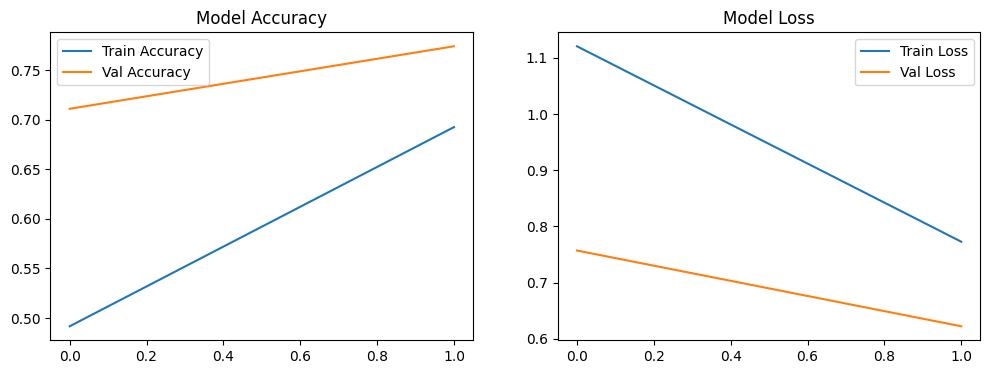

✅ Model saved at: /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5


In [ ]:
# ================= Step 1: Setup and Imports =================
!pip install tensorflow keras matplotlib numpy opencv-python pandas --quiet

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Reshape, Dense, multiply, Conv2D, Concatenate, Dropout, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from google.colab import drive

# ================= Step 2: Mount Google Drive =================
drive.mount('/content/drive', force_remount=True)

DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"
expected_classes = ['pituitary', 'glioma', 'meningioma', 'notumor']

# ================= Step 3: Ensure all folders exist =================
for split in ['Training', 'Testing']:
    split_path = os.path.join(DATASET_DIR, split)
    os.makedirs(split_path, exist_ok=True)
    for cls in expected_classes:
        class_folder = os.path.join(split_path, cls)
        os.makedirs(class_folder, exist_ok=True)

# ================= Step 4: Build DataFrame =================
file_paths = []
labels = []

train_path = os.path.join(DATASET_DIR, 'Training')
for class_name in expected_classes:
    class_folder = os.path.join(train_path, class_name)
    if os.path.isdir(class_folder):
        files = [f for f in os.listdir(class_folder) if os.path.isfile(os.path.join(class_folder, f))]
        for file_name in files:
            file_paths.append(os.path.join(class_folder, file_name))
            labels.append(class_name)

df = pd.DataFrame({'filename': file_paths, 'class': labels}).sample(frac=1, random_state=42).reset_index(drop=True)

if df.empty:
    raise ValueError("❌ No images found! Upload images to the class folders.")

train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

# ================= Step 5: Data Augmentation & Generators =================
IMG_SIZE = (128, 128)  # smaller image for faster training
BATCH_SIZE = 64         # larger batch → fewer steps

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)
val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
num_classes = len(train_generator.class_indices)

# ================= Step 6: Attention & Multi-Scale Blocks =================
def squeeze_excite_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = GlobalAveragePooling2D()(input_tensor)
    se = Reshape((1,1,filters))(se)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    return multiply([input_tensor, se])

def multi_scale_block(input_tensor):
    # Reduced filters for faster execution
    conv3 = Conv2D(32, (3,3), padding='same', activation='relu')(input_tensor)
    conv5 = Conv2D(32, (5,5), padding='same', activation='relu')(input_tensor)
    conv7 = Conv2D(32, (7,7), padding='same', activation='relu')(input_tensor)
    merged = Concatenate()([conv3, conv5, conv7])
    attention = squeeze_excite_block(merged)
    return attention

# ================= Step 7: Build Model =================
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = multi_scale_block(inputs)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)
x = multi_scale_block(x)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)
x = Flatten()(x)
x = Dense(128, activation='relu')(x)  # reduced dense units for speed
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# ================= Step 8: Callbacks =================
checkpoint_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5'
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# ================= Step 9: Train Model =================
history = model.fit(
    train_generator,
    epochs=2,  # fewer epochs for testing / faster run
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop]
)

# ================= Step 10: Plot Performance =================
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Model Loss')
plt.show()

# ================= Step 11: Save Final Model =================
final_model_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5'
model.save(final_model_path)
print(f"✅ Model saved at: {final_model_path}")


Mounted at /content/drive
Found 4570 validated image filenames belonging to 4 classes.
Found 1142 validated image filenames belonging to 4 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      2,432 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,736 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ conv2d[0][0],     │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0],   │
│                     │                   │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ concatenate[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 96)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 6)   │        582 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 96)  │        672 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 128, 128,  │          0 │ concatenate[0][0… │
│                     │ 96)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 64,    │          0 │ max_pooling2d[0]… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     27,680 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     76,832 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    150,560 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64,    │          0 │ conv2d_3[0][0],   │
│ (Concatenate)       │ 96)               │            │ conv2d_4[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ concatenate_1[0]… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 12,849,200 (49.02 MB)

 Trainable params: 12,849,200 (49.02 MB)

...

72/72 ━━━━━━━━━━━━━━━━━━━━ 1594s 22s/step - accuracy: 0.3302 - loss: 1.6420 - val_accuracy: 0.4965 - val_loss: 1.0383
Epoch 2/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18s/step - accuracy: 0.5419 - loss: 1.0671 
Epoch 2: val_loss improved from 1.03834 to 0.77941, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1382s 19s/step - accuracy: 0.5423 - loss: 1.0662 - val_accuracy: 0.6979 - val_loss: 0.7794
Epoch 3/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18s/step - accuracy: 0.6437 - loss: 0.8536 
Epoch 3: val_loss improved from 0.77941 to 0.67762, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1382s 19s/step - accuracy: 0.6440 - loss: 0.8532 - val_accuracy: 0.7539 - val_loss: 0.6776
Epoch 4/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18s/step - accuracy: 0.6966 - loss: 0.7706 
Epoch 4: val_loss improved from 0.67762 to 0.63747, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1390s 19s/step - accuracy: 0.6967 - loss: 0.7701 - val_accuracy: 0.7662 - val_loss: 0.6375
Epoch 5/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18s/step - accuracy: 0.7228 - loss: 0.6922 
Epoch 5: val_loss improved from 0.63747 to 0.54555, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1399s 19s/step - accuracy: 0.7229 - loss: 0.6919 - val_accuracy: 0.7828 - val_loss: 0.5455


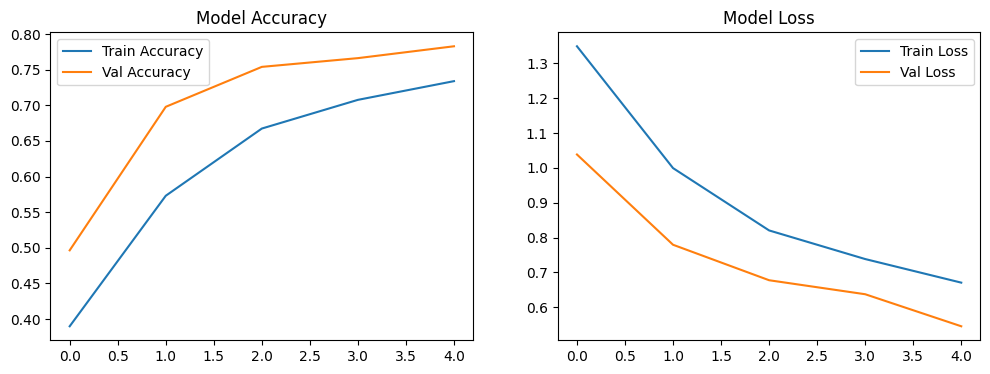

✅ Model saved at: /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5


In [ ]:
!pip install tensorflow keras matplotlib numpy opencv-python pandas --quiet

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Reshape, Dense, multiply, Conv2D, Concatenate, Dropout, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"
expected_classes = ['pituitary', 'glioma', 'meningioma', 'notumor']

for split in ['Training', 'Testing']:
    split_path = os.path.join(DATASET_DIR, split)
    os.makedirs(split_path, exist_ok=True)
    for cls in expected_classes:
        class_folder = os.path.join(split_path, cls)
        os.makedirs(class_folder, exist_ok=True)

file_paths = []
labels = []

train_path = os.path.join(DATASET_DIR, 'Training')
for class_name in expected_classes:
    class_folder = os.path.join(train_path, class_name)
    if os.path.isdir(class_folder):
        files = [f for f in os.listdir(class_folder) if os.path.isfile(os.path.join(class_folder, f))]
        for file_name in files:
            file_paths.append(os.path.join(class_folder, file_name))
            labels.append(class_name)

df = pd.DataFrame({'filename': file_paths, 'class': labels}).sample(frac=1, random_state=42).reset_index(drop=True)

if df.empty:
    raise ValueError("❌ No images found! Upload images to the class folders.")

train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

IMG_SIZE = (128, 128)
BATCH_SIZE = 64

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)
val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
num_classes = len(train_generator.class_indices)

def squeeze_excite_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = GlobalAveragePooling2D()(input_tensor)
    se = Reshape((1,1,filters))(se)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    return multiply([input_tensor, se])

def multi_scale_block(input_tensor):
    # Reduced filters for faster execution
    conv3 = Conv2D(32, (3,3), padding='same', activation='relu')(input_tensor)
    conv5 = Conv2D(32, (5,5), padding='same', activation='relu')(input_tensor)
    conv7 = Conv2D(32, (7,7), padding='same', activation='relu')(input_tensor)
    merged = Concatenate()([conv3, conv5, conv7])
    attention = squeeze_excite_block(merged)
    return attention

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = multi_scale_block(inputs)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)
x = multi_scale_block(x)
x = MaxPooling2D(pool_size=2)(x)
x = Dropout(0.3)(x)
x = Flatten()(x)
x = Dense(128, activation='relu')(x)  # reduced dense units for speed
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()
checkpoint_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5'
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(
    train_generator,
    epochs=5,  # fewer epochs for testing / faster run
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop]
)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Model Loss')
plt.show()
final_model_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_brain_tumor.h5'
model.save(final_model_path)
print(f"✅ Model saved at: {final_model_path}")


In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

checkpoint_path = '/content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5'
model = tf.keras.models.load_model(checkpoint_path, compile=False)  # don't compile yet

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

checkpoint = ModelCheckpoint(
    checkpoint_path, save_best_only=True, verbose=1
)
early_stop = EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)
lr_schedule = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1
)

history2 = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop, lr_schedule],
    initial_epoch=5  # continue from epoch 6
)


Epoch 6/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 22s/step - accuracy: 0.7280 - loss: 0.6808 
Epoch 6: val_loss improved from inf to 0.51479, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1711s 24s/step - accuracy: 0.7283 - loss: 0.6805 - val_accuracy: 0.8091 - val_loss: 0.5148 - learning_rate: 0.0010
Epoch 7/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - accuracy: 0.7823 - loss: 0.6062 
Epoch 7: val_loss did not improve from 0.51479
72/72 ━━━━━━━━━━━━━━━━━━━━ 1739s 24s/step - accuracy: 0.7822 - loss: 0.6063 - val_accuracy: 0.7933 - val_loss: 0.5339 - learning_rate: 0.0010
Epoch 8/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 22s/step - accuracy: 0.7701 - loss: 0.5977 
Epoch 8: val_loss did not improve from 0.51479

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
72/72 ━━━━━━━━━━━━━━━━━━━━ 1779s 24s/step - accuracy: 0.7701 - loss: 0.5978 - val_accuracy: 0.7890 - val_loss: 0.5756 - learning_rate: 0.0010
Epoch 9/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 22s/step - accuracy: 0.7835 - loss: 0.5605 
Epoch 9: val_loss improved from 0.51479 to 0.49210, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1713s 24s/step - accuracy: 0.7835 - loss: 0.5605 - val_accuracy: 0.8161 - val_loss: 0.4921 - learning_rate: 5.0000e-04
Epoch 10/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 22s/step - accuracy: 0.7901 - loss: 0.5475 
Epoch 10: val_loss improved from 0.49210 to 0.46087, saving model to /content/drive/MyDrive/Brain_Tumor/multi_scale_attention_cnn_checkpoint.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 1746s 24s/step - accuracy: 0.7901 - loss: 0.5476 - val_accuracy: 0.8161 - val_loss: 0.4609 - learning_rate: 5.0000e-04


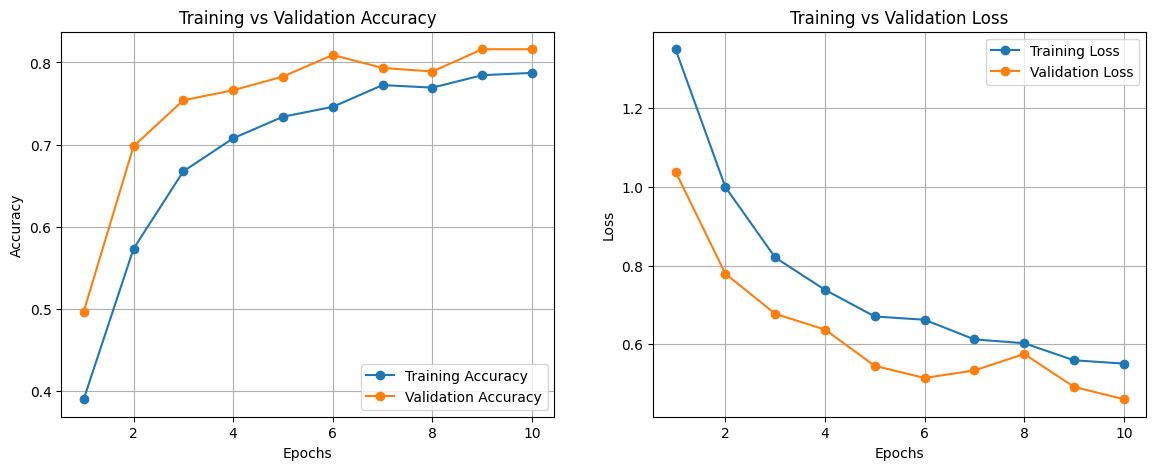

In [ ]:
import matplotlib.pyplot as plt

# Combine history from first training and continued training
# If you have both histories:
# history.history -> epochs 1–5
# history2.history -> epochs 6–10
# Otherwise, just use `history.history` if you continued training in the same model

# Example combining histories (replace history2 with your continued training history variable)
acc = history.history['accuracy'] + history2.history['accuracy']
val_acc = history.history['val_accuracy'] + history2.history['val_accuracy']
loss = history.history['loss'] + history2.history['loss']
val_loss = history.history['val_loss'] + history2.history['val_loss']

epochs_range = range(1, len(acc)+1)

plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)

plt.show()


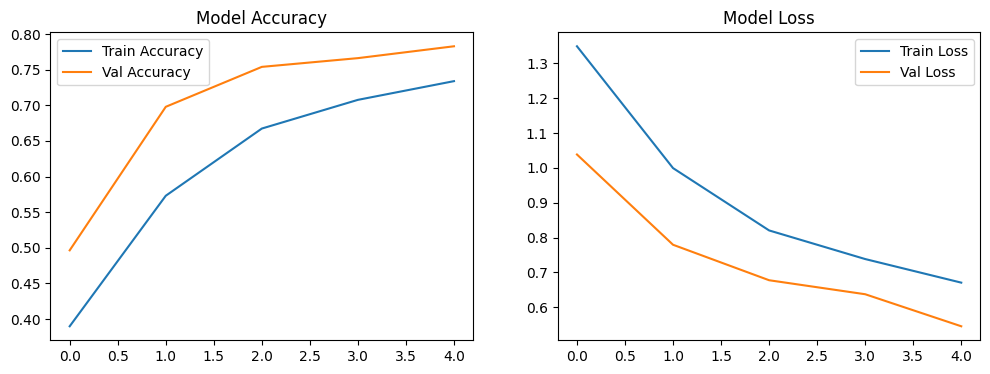

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Model Loss')
plt.show()

Mounted at /content/drive
Found 4570 validated image filenames belonging to 4 classes.
Found 1142 validated image filenames belonging to 4 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             

 Total params: 8,678,692 (33.11 MB)

 Trainable params: 8,677,796 (33.10 MB)

...

143/143 ━━━━━━━━━━━━━━━━━━━━ 1125s 8s/step - accuracy: 0.4306 - loss: 5.4788 - val_accuracy: 0.2566 - val_loss: 11.8376
Epoch 2/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.4476 - loss: 1.2882
Epoch 2: val_loss improved from 11.83757 to 1.43588, saving model to /content/drive/MyDrive/Brain_Tumor/final_cnn_model.h5


143/143 ━━━━━━━━━━━━━━━━━━━━ 734s 5s/step - accuracy: 0.4477 - loss: 1.2878 - val_accuracy: 0.2828 - val_loss: 1.4359
Epoch 3/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5199 - loss: 1.1089
Epoch 3: val_loss did not improve from 1.43588
143/143 ━━━━━━━━━━━━━━━━━━━━ 735s 5s/step - accuracy: 0.5199 - loss: 1.1089 - val_accuracy: 0.2767 - val_loss: 2.0815
Epoch 4/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5239 - loss: 1.0572
Epoch 4: val_loss did not improve from 1.43588
143/143 ━━━━━━━━━━━━━━━━━━━━ 734s 5s/step - accuracy: 0.5240 - loss: 1.0571 - val_accuracy: 0.2977 - val_loss: 1.8441
Epoch 5/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5556 - loss: 0.9972
Epoch 5: val_loss improved from 1.43588 to 1.03499, saving model to /content/drive/MyDrive/Brain_Tumor/final_cnn_model.h5


143/143 ━━━━━━━━━━━━━━━━━━━━ 787s 5s/step - accuracy: 0.5557 - loss: 0.9972 - val_accuracy: 0.5403 - val_loss: 1.0350
Epoch 6/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5786 - loss: 0.9538
Epoch 6: val_loss did not improve from 1.03499
143/143 ━━━━━━━━━━━━━━━━━━━━ 744s 5s/step - accuracy: 0.5785 - loss: 0.9542 - val_accuracy: 0.5105 - val_loss: 1.1276
Epoch 7/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5696 - loss: 0.9754
Epoch 7: val_loss did not improve from 1.03499
143/143 ━━━━━━━━━━━━━━━━━━━━ 713s 5s/step - accuracy: 0.5697 - loss: 0.9752 - val_accuracy: 0.5289 - val_loss: 1.4270
Epoch 8/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5840 - loss: 0.9404
Epoch 8: val_loss did not improve from 1.03499
143/143 ━━━━━━━━━━━━━━━━━━━━ 712s 5s/step - accuracy: 0.5841 - loss: 0.9402 - val_accuracy: 0.5806 - val_loss: 1.1721
Epoch 9/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6067 - loss: 0.8951
Epoch 9: val_loss did not improve from 1.03499


143/143 ━━━━━━━━━━━━━━━━━━━━ 746s 5s/step - accuracy: 0.6158 - loss: 0.8936 - val_accuracy: 0.5849 - val_loss: 0.9596
Epoch 11/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6151 - loss: 0.8731
Epoch 11: val_loss improved from 0.95965 to 0.90368, saving model to /content/drive/MyDrive/Brain_Tumor/final_cnn_model.h5


143/143 ━━━━━━━━━━━━━━━━━━━━ 751s 5s/step - accuracy: 0.6152 - loss: 0.8731 - val_accuracy: 0.6419 - val_loss: 0.9037
Epoch 12/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6452 - loss: 0.8472
Epoch 12: val_loss did not improve from 0.90368
143/143 ━━━━━━━━━━━━━━━━━━━━ 720s 5s/step - accuracy: 0.6453 - loss: 0.8472 - val_accuracy: 0.6357 - val_loss: 1.1716
Epoch 13/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6595 - loss: 0.8302
Epoch 13: val_loss did not improve from 0.90368
143/143 ━━━━━━━━━━━━━━━━━━━━ 761s 5s/step - accuracy: 0.6595 - loss: 0.8301 - val_accuracy: 0.5412 - val_loss: 1.8287
Epoch 14/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6411 - loss: 0.8542
Epoch 14: val_loss did not improve from 0.90368
143/143 ━━━━━━━━━━━━━━━━━━━━ 776s 5s/step - accuracy: 0.6412 - loss: 0.8541 - val_accuracy: 0.3651 - val_loss: 5.1981
Epoch 15/25
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6448 - loss: 0.8116
Epoch 15: val_loss did not improve from 

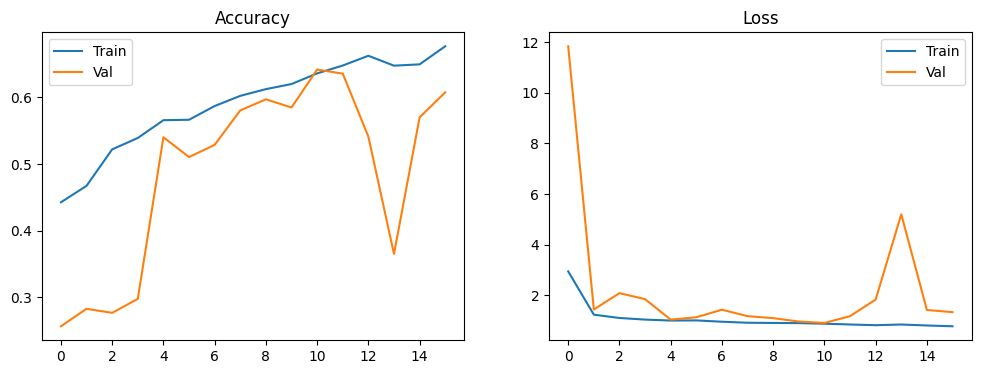

36/36 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step

CONFUSION MATRIX:
[[113  12   8 114]
 [ 72  35  37 146]
 [  1   1 300  10]
 [  2   0   6 285]]


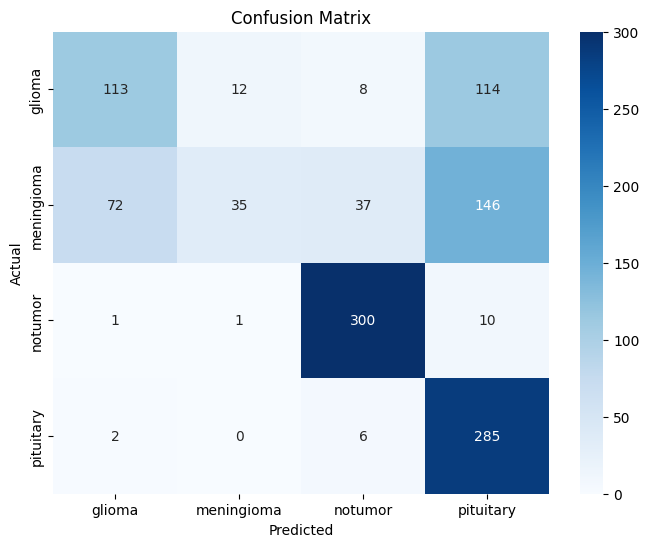


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      glioma       0.60      0.46      0.52       247
  meningioma       0.73      0.12      0.21       290
     notumor       0.85      0.96      0.90       312
   pituitary       0.51      0.97      0.67       293

    accuracy                           0.64      1142
   macro avg       0.67      0.63      0.58      1142
weighted avg       0.68      0.64      0.58      1142



In [ ]:
!pip install tensorflow keras matplotlib numpy opencv-python pandas --quiet

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# ============================
#   DATASET DIRECTORY
# ============================
DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"
classes = ["glioma", "meningioma", "notumor", "pituitary"]

# ============================
#   READ DATASET FILES
# ============================
file_paths = []
labels = []

train_path = os.path.join(DATASET_DIR, "Training")

for cls in classes:
    folder = os.path.join(train_path, cls)
    files = os.listdir(folder)
    for f in files:
        file_paths.append(os.path.join(folder, f))
        labels.append(cls)

df = pd.DataFrame({"filename": file_paths, "class": labels}).sample(frac=1, random_state=42)

train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# ============================
#   STRONG DATA AUGMENTATION
# ============================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(classes)

# ============================
#   IMPROVED CNN BLOCK
# ============================
def cnn_block(x, filters):
    x = Conv2D(filters, (3,3), padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = Conv2D(filters, (3,3), padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2,2))(x)
    x = Dropout(0.3)(x)
    return x

# ============================
#   CNN MODEL
# ============================
inputs = layers.Input(shape=(128, 128, 3))

x = cnn_block(inputs, 32)
x = cnn_block(x, 64)
x = cnn_block(x, 128)

x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# ============================
#   CLASS WEIGHTS (important!)
# ============================
cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['class']),
    y=train_df['class']
)
class_weights = dict(zip(np.unique(train_df['class']), cw))
print("CLASS WEIGHTS:", class_weights)

# ============================
#   TRAIN MODEL
# ============================
checkpoint_path = "/content/drive/MyDrive/Brain_Tumor/final_cnn_model.h5"
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, verbose=1)
early_stop = EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss')

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=25,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop]
)

# ============================
#   PLOT ACCURACY & LOSS
# ============================
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")
plt.legend(["Train","Val"])

plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.legend(["Train","Val"])
plt.show()

# ============================
#   CONFUSION MATRIX
# ============================
y_pred = model.predict(val_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = val_generator.classes
labels = list(val_generator.class_indices.keys())

cm = confusion_matrix(y_true, y_pred_classes)

print("\nCONFUSION MATRIX:")
print(cm)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ============================
#   CLASSIFICATION REPORT
# ============================
print("\nCLASSIFICATION REPORT:")
print(classification_report(y_true, y_pred_classes, target_names=labels))


In [ ]:
# ----------------------------
# Dual-Stream ROI + Full EfficientNetB3
# ----------------------------
# Run in Google Colab
!pip install -q tensorflow==2.12.0 matplotlib seaborn opencv-python

import os, random, math
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.utils import to_categorical, Sequence
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report
from google.colab import drive

# ----------------------------
# Mount Google Drive
# ----------------------------
drive.mount('/content/drive', force_remount=True)

# ----------------------------
# Configuration - CHANGE IF NEEDED
# ----------------------------
DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"   # <-- change if your path is different
TRAIN_DIR = os.path.join(DATASET_DIR, "Training")
TEST_DIR  = os.path.join(DATASET_DIR, "Testing")    # optional, we'll use Training split for train/val
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = 300   # EfficientNetB3 recommended
BATCH_SIZE = 8   # reduce if GPU OOM
EPOCHS = 18
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ----------------------------
# Utility: ROI Extraction
# ----------------------------
def extract_roi_rgb(img):
    """
    Input: BGR image (as read by cv2)
    Output: ROI-cropped RGB image (or full if ROI not found)
    Strategy: convert to grayscale, blur, Otsu threshold, find largest contour.
    """
    if img is None:
        return None
    # work on grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5,5), 0)
    # Otsu threshold may capture background; use morphological ops to reduce noise
    _, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # invert threshold if background is white
    # ensure tumor area is foreground: compare mean intensity
    if np.mean(gray[thresh==255]) > np.mean(gray[thresh==0]):
        thresh = cv2.bitwise_not(thresh)
    # morphological closing
    kernel = np.ones((5,5), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        # fallback: return center crop
        h, w = img.shape[:2]
        min_side = min(h,w)
        cy, cx = h//2, w//2
        half = min_side//2
        crop = img[cy-half:cy+half, cx-half:cx+half]
        return crop if crop.size else img
    # choose largest contour
    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    # pad bounding box a bit
    pad = int(0.10 * max(w,h))
    x1 = max(0, x - pad); y1 = max(0, y - pad)
    x2 = min(img.shape[1], x + w + pad); y2 = min(img.shape[0], y + h + pad)
    roi = img[y1:y2, x1:x2]
    if roi.size == 0:
        return img
    return roi

# ----------------------------
# Gather dataset filepaths and labels
# ----------------------------
def gather_file_list(root_dir, classes):
    files, labels = [], []
    for cls in classes:
        folder = os.path.join(root_dir, cls)
        if not os.path.isdir(folder):
            continue
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            # simple check for image extensions
            if not fname.lower().endswith(('.png','.jpg','.jpeg','.bmp','.tif','.tiff')):
                continue
            files.append(fpath)
            labels.append(cls)
    return files, labels

all_files, all_labels = gather_file_list(TRAIN_DIR, CLASSES)
if len(all_files) == 0:
    raise ValueError("No training images found. Check DATASET_DIR and folder structure.")

df = pd.DataFrame({"filename": all_files, "class": all_labels})
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

# stratified train/val split
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(df, test_size=0.18, random_state=SEED, stratify=df['class'])

print("Train samples:", len(train_df), "Val samples:", len(val_df))

# ----------------------------
# Data Generator (Dual-input)
# ----------------------------
def random_augment(img):
    """Simple augmentation using cv2: random flip, small rotation, brightness"""
    # flip
    if random.random() < 0.5:
        img = cv2.flip(img, 1)
    # rotate small angle
    if random.random() < 0.5:
        angle = random.uniform(-15,15)
        h,w = img.shape[:2]
        M = cv2.getRotationMatrix2D((w/2,h/2), angle, 1.0)
        img = cv2.warpAffine(img, M, (w,h), borderMode=cv2.BORDER_REFLECT)
    # brightness
    if random.random() < 0.5:
        factor = random.uniform(0.8,1.2)
        img = np.clip(img * factor, 0, 255).astype(np.uint8)
    return img

class DualImageSequence(Sequence):
    def __init__(self, df, classes, batch_size=BATCH_SIZE, img_size=IMG_SIZE, augment=False, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.img_size = img_size
        self.augment = augment
        self.shuffle = shuffle
        self.classes = classes
        self.on_epoch_end()
    def __len__(self):
        return math.ceil(len(self.df) / self.batch_size)
    def on_epoch_end(self):
        self.indexes = np.arange(len(self.df))
        if self.shuffle:
            np.random.shuffle(self.indexes)
    def __getitem__(self, idx):
        batch_indexes = self.indexes[idx*self.batch_size:(idx+1)*self.batch_size]
        batch_rows = self.df.iloc[batch_indexes]
        full_batch = np.zeros((len(batch_rows), self.img_size, self.img_size, 3), dtype=np.float32)
        roi_batch  = np.zeros((len(batch_rows), self.img_size, self.img_size, 3), dtype=np.float32)
        y = np.zeros((len(batch_rows), len(self.classes)), dtype=np.float32)
        for i, (_, row) in enumerate(batch_rows.iterrows()):
            fpath = row['filename']
            label = row['class']
            img = cv2.imread(fpath)
            if img is None:
                # skip bad file with black image
                img = np.zeros((self.img_size, self.img_size, 3), dtype=np.uint8)
            # produce full image input
            full = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            if self.augment:
                full = random_augment(full)
            full = cv2.resize(full, (self.img_size, self.img_size))
            full = full.astype(np.float32) / 255.0
            # produce roi input
            roi_img = extract_roi_rgb(img)
            roi = cv2.cvtColor(roi_img, cv2.COLOR_BGR2RGB)
            if self.augment:
                roi = random_augment(roi)
            roi = cv2.resize(roi, (self.img_size, self.img_size))
            roi = roi.astype(np.float32) / 255.0
            full_batch[i] = full
            roi_batch[i] = roi
            y[i, self.classes.index(label)] = 1.0
        return [full_batch, roi_batch], y

# Create generators
train_seq = DualImageSequence(train_df, CLASSES, batch_size=BATCH_SIZE, img_size=IMG_SIZE, augment=True, shuffle=True)
val_seq   = DualImageSequence(val_df, CLASSES, batch_size=BATCH_SIZE, img_size=IMG_SIZE, augment=False, shuffle=False)

# ----------------------------
# Compute class weights
# ----------------------------
y_train_labels = train_df['class'].values
unique_classes = np.array(CLASSES)
cw_values = compute_class_weight(class_weight='balanced', classes=unique_classes, y=y_train_labels)
class_weights = {i: cw_values[i] for i in range(len(unique_classes))}
print("Class weights (index->weight):", class_weights)

# ----------------------------
# Build Dual-EfficientNetB3 Model
# ----------------------------
# Stream A: full image
base_full = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
x_full = base_full.output
x_full = layers.GlobalAveragePooling2D()(x_full)
x_full = layers.Dropout(0.3)(x_full)

# Stream B: ROI
base_roi = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
x_roi = base_roi.output
x_roi = layers.GlobalAveragePooling2D()(x_roi)
x_roi = layers.Dropout(0.3)(x_roi)

# Optionally freeze most layers initially (fine-tune later)
for layer in base_full.layers[:-40]:
    layer.trainable = False
for layer in base_roi.layers[:-40]:
    layer.trainable = False

# Fuse
combined = layers.Concatenate()([x_full, x_roi])
combined = layers.Dense(512, activation='relu')(combined)
combined = layers.BatchNormalization()(combined)
combined = layers.Dropout(0.4)(combined)
combined = layers.Dense(128, activation='relu')(combined)
combined = layers.Dropout(0.3)(combined)
outputs = layers.Dense(len(CLASSES), activation='softmax')(combined)

model = Model(inputs=[base_full.input, base_roi.input], outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

# ----------------------------
# Callbacks
# ----------------------------
checkpoint_path = os.path.join(DATASET_DIR, "dual_effnetb3_best.h5")
checkpoint = ModelCheckpoint(checkpoint_path, monitor='val_loss', verbose=1, save_best_only=True, save_weights_only=False)
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# ----------------------------
# Train
# ----------------------------
history = model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop],
    verbose=1
)

# Save final model
final_path = os.path.join(DATASET_DIR, "dual_effnetb3_final.h5")
model.save(final_path)
print("Saved final model to:", final_path)

# ----------------------------
# Evaluation: predictions, confusion matrix, report
# ----------------------------
# Predict on validation set
y_true = []
y_pred = []

for (X,y) in val_seq:
    preds = model.predict(X)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(y, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASSES))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Validation)")
plt.show()

# Plot training curves
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(history.history['accuracy'], label='train_acc'); plt.plot(history.history['val_accuracy'], label='val_acc'); plt.legend(); plt.title('Accuracy')
plt.subplot(1,2,2); plt.plot(history.history['loss'], label='train_loss'); plt.plot(history.history['val_loss'], label='val_loss'); plt.legend(); plt.title('Loss')
plt.show()




ERROR: Could not find a version that satisfies the requirement tensorflow==2.12.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0)
ERROR: No matching distribution found for tensorflow==2.12.0
Mounted at /content/drive
Train samples: 4683 Val samples: 1029
Class weights (index->weight): {0: np.float64(1.0810249307479225), 1: np.float64(1.0662568306010929), 2: np.float64(0.8950688073394495), 3: np.float64(0.9805276381909548)}
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


ValueError: The name "stem_conv_pad" is used 2 times in the model. All operation names should be unique.

ERROR: Could not find a version that satisfies the requirement tensorflow==2.12.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0)
ERROR: No matching distribution found for tensorflow==2.12.0
Mounted at /content/drive
Found 4570 validated image filenames belonging to 4 classes.
Found 1142 validated image filenames belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,184,179 (42.66 MB)

 Trainable params: 397,572 (1.52 MB)

...

286/286 ━━━━━━━━━━━━━━━━━━━━ 1653s 6s/step - accuracy: 0.7868 - loss: 0.6339 - val_accuracy: 0.8757 - val_loss: 0.3554
Epoch 4/8
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8079 - loss: 0.5683
Epoch 4: val_accuracy improved from 0.87566 to 0.87741, saving model to /content/drive/MyDrive/Brain_Tumor/effnetb3_best.h5


286/286 ━━━━━━━━━━━━━━━━━━━━ 1651s 6s/step - accuracy: 0.8079 - loss: 0.5682 - val_accuracy: 0.8774 - val_loss: 0.3346
Epoch 5/8
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8234 - loss: 0.4933
Epoch 5: val_accuracy did not improve from 0.87741
286/286 ━━━━━━━━━━━━━━━━━━━━ 1732s 6s/step - accuracy: 0.8234 - loss: 0.4934 - val_accuracy: 0.8730 - val_loss: 0.3401
Epoch 6/8
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8350 - loss: 0.4807
Epoch 6: val_accuracy improved from 0.87741 to 0.88354, saving model to /content/drive/MyDrive/Brain_Tumor/effnetb3_best.h5


286/286 ━━━━━━━━━━━━━━━━━━━━ 1629s 6s/step - accuracy: 0.8350 - loss: 0.4807 - val_accuracy: 0.8835 - val_loss: 0.2970
Epoch 7/8
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8431 - loss: 0.4631
Epoch 7: val_accuracy improved from 0.88354 to 0.89317, saving model to /content/drive/MyDrive/Brain_Tumor/effnetb3_best.h5


286/286 ━━━━━━━━━━━━━━━━━━━━ 1633s 6s/step - accuracy: 0.8431 - loss: 0.4631 - val_accuracy: 0.8932 - val_loss: 0.2754
Epoch 8/8
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8365 - loss: 0.4864
Epoch 8: val_accuracy improved from 0.89317 to 0.89580, saving model to /content/drive/MyDrive/Brain_Tumor/effnetb3_best.h5


286/286 ━━━━━━━━━━━━━━━━━━━━ 1622s 6s/step - accuracy: 0.8365 - loss: 0.4863 - val_accuracy: 0.8958 - val_loss: 0.2716
Restoring model weights from the end of the best epoch: 8.


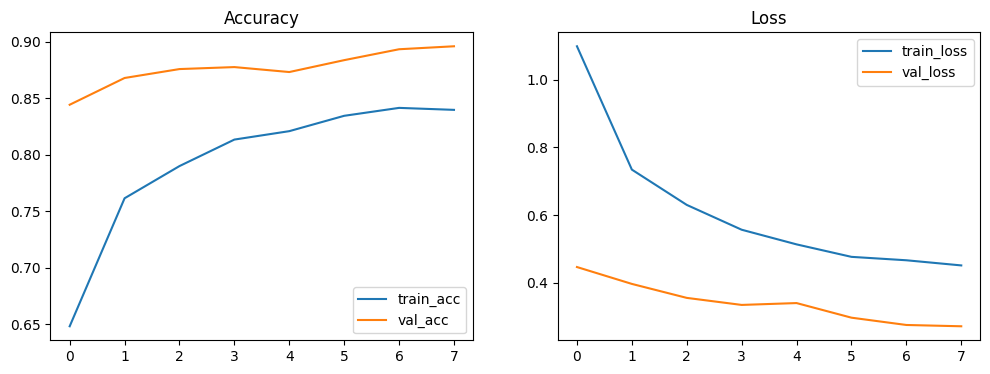

72/72 ━━━━━━━━━━━━━━━━━━━━ 314s 4s/step


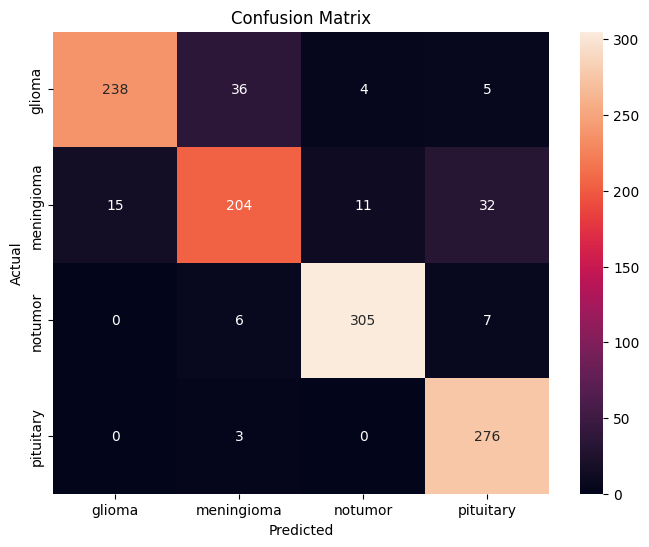

Classification Report:
              precision    recall  f1-score   support

      glioma       0.94      0.84      0.89       283
  meningioma       0.82      0.78      0.80       262
     notumor       0.95      0.96      0.96       318
   pituitary       0.86      0.99      0.92       279

    accuracy                           0.90      1142
   macro avg       0.89      0.89      0.89      1142
weighted avg       0.90      0.90      0.89      1142

Final model saved to: /content/drive/MyDrive/Brain_Tumor/effnetb3_final.h5


In [ ]:
# !pip install -q tensorflow==2.12.0 scikit-learn matplotlib pandas opencv-python

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from google.colab import drive

# it is located in mount drive with their data paths

drive.mount('/content/drive', force_remount=True)
DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor"
expected_classes = ['pituitary', 'glioma', 'meningioma', 'notumor']

# To Ensure folders exist
for split in ['Training', 'Testing']:
    for cls in expected_classes:
        os.makedirs(os.path.join(DATASET_DIR, split, cls), exist_ok=True)

# from training it bulids the dataframe
file_paths = []
labels = []
train_path = os.path.join(DATASET_DIR, 'Training')
for class_name in expected_classes:
    class_folder = os.path.join(train_path, class_name)
    if os.path.isdir(class_folder):
        for fname in os.listdir(class_folder):
            fpath = os.path.join(class_folder, fname)
            if os.path.isfile(fpath):
                file_paths.append(fpath)
                labels.append(class_name)

df = pd.DataFrame({'filename': file_paths, 'class': labels}).sample(frac=1, random_state=42).reset_index(drop=True)
if df.empty:
    raise ValueError("No images found in Training folder. Upload images and retry.")

train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)


# Hyperparams with efficientnetB3

IMG_SIZE = (300, 300)
BATCH_SIZE = 16
SEED = 42

# Image generators for use preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)
val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)
print("Class indices:", train_generator.class_indices)


# EfficientNetB3 backbone + top classifier(Model)

base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
base_model.trainable = False   # start with frozen backbone

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()


# Callbacks the code with continue checkpoint
checkpoint_path = "/content/drive/MyDrive/Brain_Tumor/effnetb3_best.h5"
callbacks = [
    ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)
]


# Train top layers used for feature extraction
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=8,
    callbacks=callbacks
)

# Plot training values
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history.get('accuracy', []), label='train_acc')
plt.plot(history.history.get('val_accuracy', []), label='val_acc')
plt.legend(); plt.title('Accuracy')
plt.subplot(1,2,2)
plt.plot(history.history.get('loss', []), label='train_loss')
plt.plot(history.history.get('val_loss', []), label='val_loss')
plt.legend(); plt.title('Loss')
plt.show()

# confusion matrix with report
# use the best weights saved by ModelCheckpoint if desired
if os.path.exists(checkpoint_path):
    model.load_weights(checkpoint_path)

y_true = val_generator.classes
y_pred_proba = model.predict(val_generator, verbose=1)
y_pred = np.argmax(y_pred_proba, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=[k for k,v in sorted(train_generator.class_indices.items(), key=lambda x:x[1])],
            yticklabels=[k for k,v in sorted(train_generator.class_indices.items(), key=lambda x:x[1])])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
plt.show()

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=[k for k,v in sorted(train_generator.class_indices.items(), key=lambda x:x[1])]))


# save final code
final_model_path = "/content/drive/MyDrive/Brain_Tumor/effnetb3_final.h5"
model.save(final_model_path)
print("Final model saved to:", final_model_path)
